In [120]:
import pandas as pd
import sys
import matplotlib.pyplot as plt

sys.path.append("..")

from src.data.load import (
    load_ratings,
    load_genres,
    load_movies,
    load_users,
)

from src.utils.config import RATING_SCALE

ratings = load_ratings()


def count_ratings(value: int) -> None:
    print(f" Number of rate '{value}': {(ratings['rating']==value).sum()}")


for value in range(RATING_SCALE[0], RATING_SCALE[1] + 1):
    count_ratings(value)

 Number of rate '1': 6110
 Number of rate '2': 11370
 Number of rate '3': 27145
 Number of rate '4': 34174
 Number of rate '5': 21201


In [3]:
voting_users = ratings.groupby("user_id")["rating"].count()
voting_users_df = voting_users.reset_index()
voting_users_df.columns = ["user_id", "count_rates"]
voting_users_df

,user_id,count_rates
0,1,272
1,2,62
2,3,54
3,4,24
4,5,175
...,...,...
938,939,49
939,940,107
940,941,22
941,942,79


In [4]:
voting_users.describe()

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
Name: rating, dtype: float64

Text(0.5, 1.0, "Users' activity distribution")

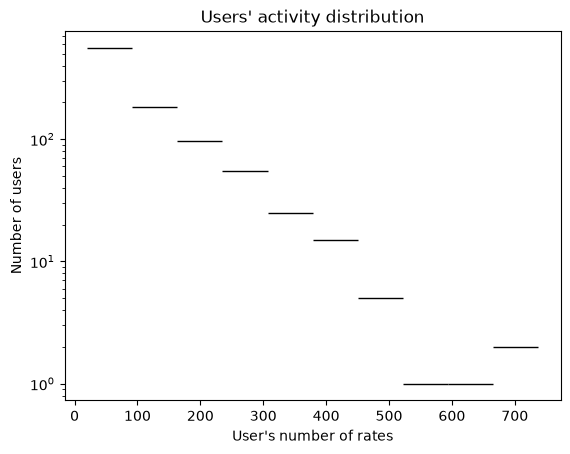

In [5]:
import seaborn as sns

hist_users = sns.histplot(voting_users, bins=10, log_scale=(False, True))
hist_users.set_xlabel("User's number of rates")
hist_users.set_ylabel("Number of users")
hist_users.set_title("Users' activity distribution")

In [6]:
movies_count_rated = ratings.groupby("movie_id")["rating"].count()
movies_count_rated.describe()

count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
Name: rating, dtype: float64

Text(0.5, 1.0, 'Distribution of How many times were films rated')

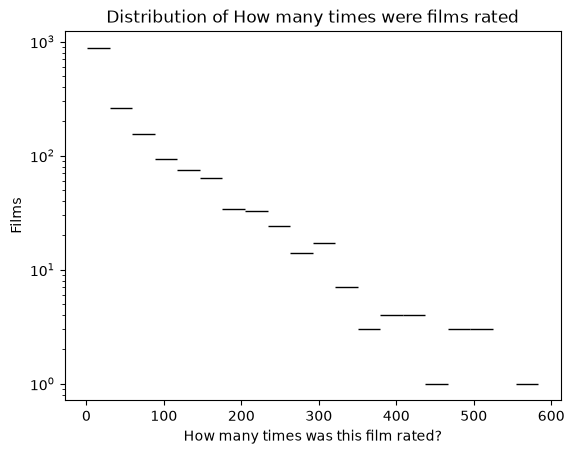

In [7]:
counted_movies = sns.histplot(movies_count_rated, bins=20, log_scale=(False, True))
counted_movies.set_xlabel("How many times was this film rated?")
counted_movies.set_ylabel("Films")
counted_movies.set_title("Distribution of How many times were films rated")

In [8]:
movies_count_rated.sort_values(ascending=False)

movie_id
50      583
258     509
100     508
181     507
294     485
       ... 
1626      1
1630      1
1632      1
1681      1
1682      1
Name: rating, Length: 1682, dtype: int64

In [9]:
movies = load_movies()
movies_count_rated_df = movies_count_rated.reset_index()
movies_count_rated_df.columns = ["movie_id", "count_rates"]
top_rated_films = pd.merge(movies, movies_count_rated_df, how="left")
top_rated_films = top_rated_films.sort_values("count_rates", ascending=False)
top_rated_films.head(20)

,movie_id,title,release_date,count_rates
49,50,Star Wars (1977),01-Jan-1977,583
257,258,Contact (1997),11-Jul-1997,509
99,100,Fargo (1996),14-Feb-1997,508
180,181,Return of the Jedi (1983),14-Mar-1997,507
293,294,Liar Liar (1997),21-Mar-1997,485
285,286,"English Patient, The (1996)",15-Nov-1996,481
287,288,Scream (1996),20-Dec-1996,478
0,1,Toy Story (1995),01-Jan-1995,452
299,300,Air Force One (1997),01-Jan-1997,431
120,121,Independence Day (ID4) (1996),03-Jul-1996,429


Text(0.5, 1.0, 'Top 20 most rated movies')

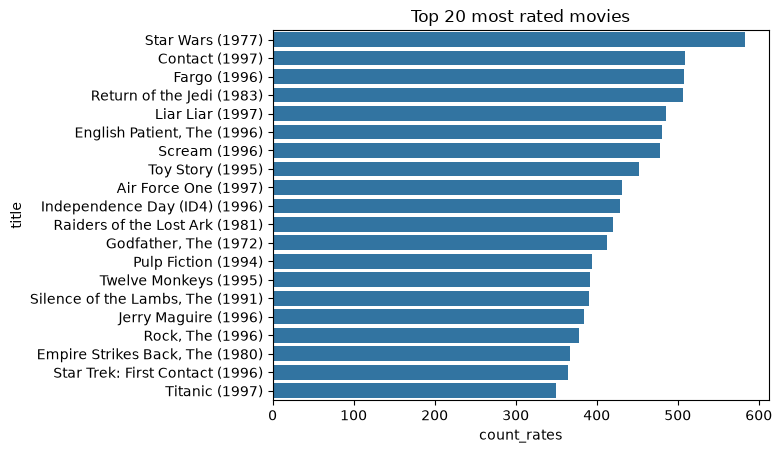

In [10]:
top_films_bar_chart = sns.barplot(data=top_rated_films[:20], x="count_rates", y="title")
top_films_bar_chart.set_title("Top 20 most rated movies")

In [11]:
avg_ratings = ratings.groupby("movie_id")["rating"].agg(["count", "mean"])
mask = avg_ratings["count"] >= 50
avg_ratings = avg_ratings[mask]
avg_ratings = avg_ratings.sort_values("mean", ascending=False)
avg_ratings

,count,mean
movie_id,,
408,112,4.491071
318,298,4.466443
169,118,4.466102
483,243,4.456790
114,67,4.447761
...,...,...
122,106,2.339623
988,86,2.313953
120,67,2.238806


In [12]:
avg_ratings_df = avg_ratings.reset_index()
avg_ratings_df.columns = ["movie_id", "count_rates", "avg_rate"]
top_avg_rated_movies = pd.merge(movies, avg_ratings_df, how="left")
top_avg_rated_movies = top_avg_rated_movies.dropna()
top_avg_rated_movies = top_avg_rated_movies.sort_values("avg_rate", ascending=False)
top_avg_rated_movies

,movie_id,title,release_date,count_rates,avg_rate
407,408,"Close Shave, A (1995)",28-Apr-1996,112.0,4.491071
317,318,Schindler's List (1993),01-Jan-1993,298.0,4.466443
168,169,"Wrong Trousers, The (1993)",01-Jan-1993,118.0,4.466102
482,483,Casablanca (1942),01-Jan-1942,243.0,4.456790
113,114,Wallace & Gromit: The Best of Aardman Animatio...,05-Apr-1996,67.0,4.447761
...,...,...,...,...,...
121,122,"Cable Guy, The (1996)",14-Jun-1996,106.0,2.339623
987,988,"Beautician and the Beast, The (1997)",07-Feb-1997,86.0,2.313953
119,120,Striptease (1996),28-Jun-1996,67.0,2.238806
686,687,McHale's Navy (1997),18-Apr-1997,69.0,2.188406


Text(0.5, 1.0, 'Top 20 best rated films')

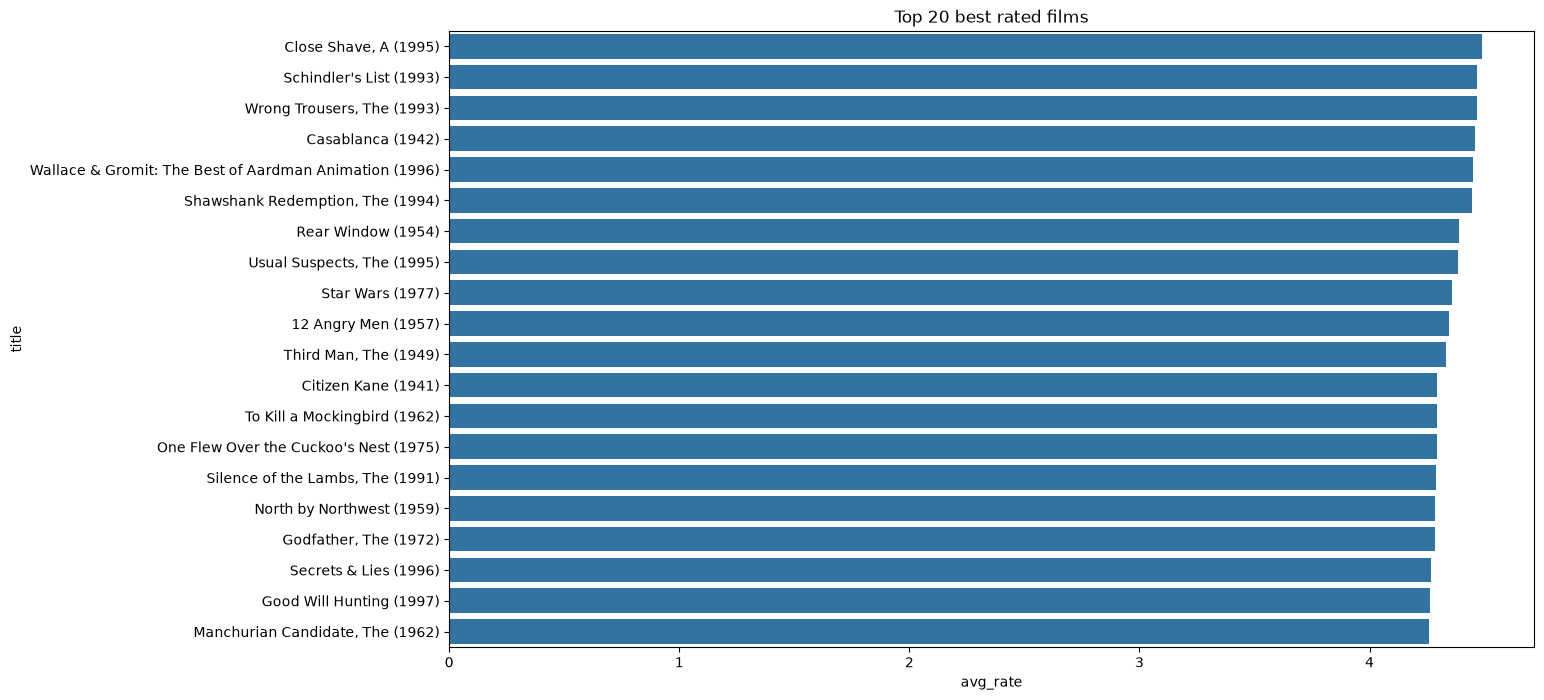

In [121]:
plt.figure(figsize=(14,8))
top_20_best_rated_chart = sns.barplot(
    data=top_avg_rated_movies[:20], x="avg_rate", y="title"
)
top_20_best_rated_chart.set_title("Top 20 best rated films")

In [14]:
def show_info() -> None:
    no_of_users = ratings["user_id"].nunique()
    no_of_films = ratings["movie_id"].nunique()
    pairs = no_of_films * no_of_users
    filled = round(100 * len(ratings) / pairs, 2)
    print(f"Number of users: {no_of_users}")
    print(f"Number of films: {no_of_films}")
    print(f"Number of possible pairs: {pairs}")
    print(f"Filled: {len(ratings)}")
    print(f"Percentage of filled: {filled}%")
    print(f"Percentage of unfilled: {100-filled}%")


show_info()

Number of users: 943
Number of films: 1682
Number of possible pairs: 1586126
Filled: 100000
Percentage of filled: 6.3%
Percentage of unfilled: 93.7%


In [109]:


top_voting_30_users=voting_users_df.sort_values("count_rates",ascending=False)["user_id"][:30].tolist()
top_voting_30_users

top_300_rated_films=top_rated_films.sort_values("count_rates",ascending=False)["movie_id"][:300].tolist()
top_300_rated_films



[50,
 258,
 100,
 181,
 294,
 286,
 288,
 1,
 300,
 121,
 174,
 127,
 56,
 7,
 98,
 237,
 117,
 172,
 222,
 313,
 204,
 405,
 79,
 210,
 151,
 173,
 69,
 748,
 168,
 269,
 257,
 195,
 423,
 9,
 318,
 276,
 22,
 302,
 328,
 96,
 118,
 25,
 15,
 183,
 216,
 176,
 64,
 234,
 202,
 28,
 191,
 89,
 111,
 275,
 742,
 12,
 357,
 82,
 135,
 289,
 238,
 97,
 268,
 546,
 70,
 196,
 186,
 333,
 475,
 153,
 132,
 125,
 228,
 144,
 483,
 194,
 245,
 323,
 185,
 197,
 11,
 282,
 496,
 301,
 568,
 655,
 265,
 182,
 273,
 143,
 471,
 180,
 179,
 161,
 71,
 427,
 678,
 8,
 95,
 322,
 235,
 435,
 508,
 88,
 215,
 271,
 187,
 603,
 4,
 175,
 385,
 211,
 597,
 200,
 588,
 403,
 515,
 208,
 230,
 134,
 272,
 250,
 527,
 298,
 474,
 284,
 393,
 209,
 274,
 340,
 307,
 124,
 147,
 13,
 14,
 23,
 203,
 751,
 514,
 732,
 566,
 479,
 480,
 419,
 591,
 283,
 845,
 83,
 326,
 58,
 327,
 24,
 154,
 432,
 511,
 255,
 99,
 651,
 433,
 218,
 133,
 229,
 137,
 188,
 367,
 402,
 451,
 684,
 628,
 321,
 319,
 582,
 226,

In [111]:
filtered_ratings=pd.merge(ratings,movies,how="inner",on="movie_id")
filtered_ratings

,user_id,movie_id,rating,timestamp,count_rates,title,release_date
0,303,785,3,879485318,484,Only You (1994),01-Jan-1994
1,234,1184,2,892079237,480,"Endless Summer 2, The (1994)",01-Jan-1994
2,308,1,4,887736532,397,Toy Story (1995),01-Jan-1995
3,181,1081,1,878962623,435,Curdled (1996),27-Sep-1996
4,276,796,1,874791932,518,Speechless (1994),01-Jan-1994
...,...,...,...,...,...,...,...
19830,279,64,1,875308510,434,"Shawshank Redemption, The (1994)",01-Jan-1994
19831,378,78,3,880056976,375,Free Willy (1993),01-Jan-1993
19832,880,476,3,880175444,368,"First Wives Club, The (1996)",14-Sep-1996
19833,276,1090,1,874795795,518,Sliver (1993),01-Jan-1993


In [112]:
print(len(top_300_rated_films),len(top_voting_30_users))
arr_sorted_films=top_300_rated_films.copy()


300 30


In [113]:
great_ratings=filtered_ratings[filtered_ratings["user_id"].isin(top_voting_30_users)&filtered_ratings["movie_id"].isin(top_300_rated_films)]
great_ratings

,user_id,movie_id,rating,timestamp,count_rates,title,release_date
2,308,1,4,887736532,397,Toy Story (1995),01-Jan-1995
8,59,196,5,888205088,382,Dead Poets Society (1989),01-Jan-1989
10,13,526,3,882141053,636,Ben-Hur (1959),01-Jan-1959
15,279,154,5,875296291,434,Monty Python's Life of Brian (1979),01-Jan-1979
17,293,685,3,888905170,388,Executive Decision (1996),09-Mar-1996
...,...,...,...,...,...,...,...
19818,896,511,5,887158830,362,Lawrence of Arabia (1962),01-Jan-1962
19828,429,199,5,882386006,414,"Bridge on the River Kwai, The (1957)",01-Jan-1957
19829,537,443,3,886031752,490,"Birds, The (1963)",01-Jan-1963
19830,279,64,1,875308510,434,"Shawshank Redemption, The (1994)",01-Jan-1994


In [114]:
data_pivot=great_ratings.pivot_table(index="user_id",columns="movie_id",values="rating",aggfunc="count",fill_value=0)
data_pivot

movie_id,1,2,4,7,8,9,11,12,13,14,...,751,756,762,763,845,866,879,1016,1028,1047
user_id,,,,,,,,,,,,,,,,,,,,,
7,0,0,1,1,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
13,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,0,0
59,1,0,1,1,0,1,1,1,1,1,...,0,1,1,0,1,1,0,0,1,1
92,1,1,1,1,1,1,1,1,1,0,...,0,1,0,1,1,0,0,1,1,1
94,1,0,1,1,1,1,1,1,0,0,...,0,0,0,1,0,0,0,0,1,0
181,1,0,0,1,0,1,0,0,1,1,...,0,1,1,1,1,1,1,0,1,1
201,1,1,1,1,1,1,1,1,0,0,...,1,0,0,0,0,0,0,0,0,0
222,1,1,1,1,1,1,1,1,0,0,...,0,1,1,1,1,0,0,1,0,0
234,1,1,1,1,1,1,1,1,1,1,...,1,0,0,0,1,0,0,0,0,0


In [115]:
data_pivot.sum().sum()

np.int64(5953)

In [116]:
data_pivot.mean().mean()

np.float64(0.6614444444444445)

In [117]:
data_pivot=data_pivot[arr_sorted_films]
data_pivot

movie_id,50,258,100,181,294,286,288,1,300,121,...,380,192,184,663,65,123,659,762,29,214
user_id,,,,,,,,,,,,,,,,,,,,,
7,1,1,1,1,1,1,1,0,1,1,...,1,1,0,1,0,0,1,0,1,1
13,1,1,1,1,1,1,1,1,1,1,...,0,0,1,1,0,0,1,1,1,0
59,1,1,1,1,0,1,1,1,0,1,...,1,0,1,1,1,1,1,1,0,0
92,1,1,1,1,1,0,1,1,0,1,...,0,0,1,1,1,1,0,0,1,1
94,1,1,1,1,0,1,1,1,0,1,...,1,1,1,0,0,0,0,0,1,1
181,0,1,1,0,1,1,1,1,1,1,...,0,0,0,0,0,1,0,1,0,0
201,1,1,1,1,0,1,1,1,0,1,...,1,1,1,0,1,1,0,0,1,0
222,1,1,1,1,1,0,1,1,1,1,...,1,0,0,0,0,0,0,1,1,1
234,1,1,1,1,1,1,1,1,1,0,...,0,1,0,1,0,0,1,0,0,0


In [118]:
data_pivot[:10]

movie_id,50,258,100,181,294,286,288,1,300,121,...,380,192,184,663,65,123,659,762,29,214
user_id,,,,,,,,,,,,,,,,,,,,,
7,1,1,1,1,1,1,1,0,1,1,...,1,1,0,1,0,0,1,0,1,1
13,1,1,1,1,1,1,1,1,1,1,...,0,0,1,1,0,0,1,1,1,0
59,1,1,1,1,0,1,1,1,0,1,...,1,0,1,1,1,1,1,1,0,0
92,1,1,1,1,1,0,1,1,0,1,...,0,0,1,1,1,1,0,0,1,1
94,1,1,1,1,0,1,1,1,0,1,...,1,1,1,0,0,0,0,0,1,1
181,0,1,1,0,1,1,1,1,1,1,...,0,0,0,0,0,1,0,1,0,0
201,1,1,1,1,0,1,1,1,0,1,...,1,1,1,0,1,1,0,0,1,0
222,1,1,1,1,1,0,1,1,1,1,...,1,0,0,0,0,0,0,1,1,1
234,1,1,1,1,1,1,1,1,1,0,...,0,1,0,1,0,0,1,0,0,0


Text(0.5, 1.0, 'User-Item Matrix Sparity')

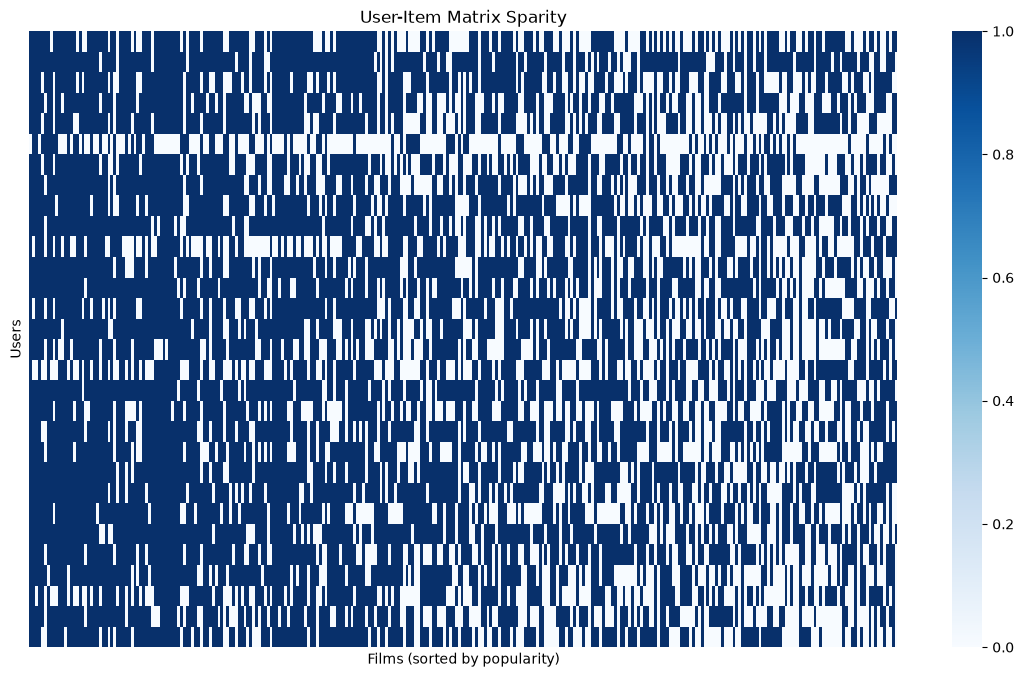

In [ ]:

plt.figure(figsize=(14,8))
pivot_heatmap=sns.heatmap(data=data_pivot,xticklabels=False,yticklabels=False,cmap="Blues")
pivot_heatmap.set_xlabel("Films (sorted by popularity)")
pivot_heatmap.set_ylabel("Users")
pivot_heatmap.set_title("User-Item Matrix Sparity")

In [128]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error 
from sklearn.svm import *


train_data,test_data=train_test_split(ratings,test_size=0.2,random_state=42)
print(train_data.shape,test_data.shape)
print(train_data["user_id"].nunique(),test_data['user_id'].nunique())
print(train_data["movie_id"].nunique(),test_data['movie_id'].nunique())

(80000, 4) (20000, 4)
943 940
1653 1411


In [134]:
group_train_data=train_data.groupby("movie_id")["rating"].agg(["mean","count"])
group_train_data_df=group_train_data.reset_index()
group_train_data_df.columns=["movie_id","avg_rating","count_rating"]
group_train_data_df.head()

,movie_id,avg_rating,count_rating
0,1,3.865330,349
1,2,3.203883,103
2,3,3.101449,69
3,4,3.549133,173
4,5,3.246377,69


In [139]:
global_mean=train_data["rating"].mean()
test_data_pred=pd.merge(test_data,group_train_data_df,how="left",on="movie_id")
test_data_pred=test_data_pred.fillna(global_mean)
RMSE=root_mean_squared_error(test_data_pred["rating"].to_list(),test_data_pred["avg_rating"].to_list())
RMSE

1.0209640682297232

In [161]:
rated_films_from_train=ratings.groupby("movie_id")["rating"].count()
rated_films_from_train_df=rated_films_from_train.reset_index()
rated_films_from_train_df.columns=["movie_id","count_rated"]
rated_films_from_train_df=rated_films_from_train_df.sort_values("count_rated",ascending=False)
top_10_films_fr_train=rated_films_from_train_df["movie_id"][:10].to_list()
top_10_films_fr_train

[50, 258, 100, 181, 294, 286, 288, 1, 300, 121]

In [162]:
likes=test_data[test_data["rating"]>=3.5]
likes

,user_id,movie_id,rating,timestamp
75721,877,381,4,882677345
19864,94,431,4,891721716
84004,598,286,5,886711452
80917,886,496,4,876031952
50074,521,184,4,884478358
...,...,...,...,...
56745,838,596,5,887064275
32595,72,591,5,880035708
29313,523,393,5,883702411
37862,606,287,4,880921656


In [163]:
hits=likes[likes["movie_id"].isin(top_10_films_fr_train)]
hits

,user_id,movie_id,rating,timestamp
84004,598,286,5,886711452
34451,589,288,5,883352536
4293,235,100,4,889655550
71222,185,50,4,883525998
45556,698,50,5,886366101
...,...,...,...,...
21691,447,288,4,878855082
45881,644,258,4,889075928
41238,644,121,5,889077344
24954,352,50,5,884289693


,users_id,movies
